In [1]:
from src.pickle_functions import load_from_pickle
from src.label_processing import create_label_multitask, create_label_filename, get_available_presence_scores_arr
from src.hyperparam_processing import get_hyperparam_from_json
from src.dataset_utils import get_dataset_from_sdk, get_fold_ids
import pandas as pd
import numpy as np
import re

2025-07-16 08:19:49.107901: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2025-07-16 08:19:50.452196: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


# Load Dataset

In [2]:
tnan = 0
nan_str = "linear_1d" + "_tnan_" + str(tnan)
length_seq = 56
length_str = "_length_" + str(length_seq)
data_ext_name_raw = nan_str + length_str

tscore_str = "_tscore_" + str(0)
data_ext_name_proc = nan_str + tscore_str + length_str

root_data_folder = "cmu_mosei"

In [3]:
param_log = get_hyperparam_from_json("param_logistics")
param_training, param_task = get_hyperparam_from_json("param_training_task")
dataset = get_dataset_from_sdk(param_log, param_task)

CMU-MOSEI dataset loaded from pickle.
The existing computational sequences in dataset are: ['OpenFace_2', 'FACET 4.2', 'COVAREP', 'glove_vectors', 'All Labels']


# Load original or partially processed data

In [4]:
image_feature_id = 'FACET 4.2'
image_dataset = dataset[image_feature_id]
audio_dataset = dataset['COVAREP']
text_dataset = dataset['glove_vectors']
label_dataset = dataset['All Labels']
train_ids, valid_ids, test_ids = get_fold_ids(param_task)

def trunc(val, decimals):
    stepper = 10 ** decimals
    return np.trunc((val * stepper)) / stepper

def process_dataset(rm_non_exploitable_data=False, rm_length_above_56=False):
    x_train, y_train, seg_train = [], [], []
    x_valid, y_valid, seg_valid = [], [], []
    x_test, y_test, seg_test = [], [], []
    x_no_split, y_no_split, seg_no_split = [], [], []

    num_missing_mod = 0
    num_not_same_length = 0
    num_nan = 0
    num_too_long_seq = 0

    pattern = re.compile('(.*)\[.*\]')
    for seg_id in dataset['All Labels'].keys():
    
        # Get video id and its image, audio, text and label features
        vid = re.search(pattern, seg_id).group(1)
                    
    
        image_seg = image_dataset[seg_id]['features'] if seg_id in image_dataset.keys() else None
        audio_seg = audio_dataset[seg_id]['features'] if seg_id in audio_dataset.keys() else None
        text_seg = text_dataset[seg_id]['features'] if seg_id in text_dataset.keys() else None
        label_seg = label_dataset[seg_id]['features']
    
        if rm_non_exploitable_data:
    
            if not (seg_id in image_dataset.keys() and seg_id in audio_dataset.keys() and seg_id in text_dataset.keys()):
                num_missing_mod += 1
                continue
                
            if not image_seg.shape[0] == audio_seg.shape[0] == text_seg.shape[0]:
                num_not_same_length += 1
                continue
    
            if not image_seg.shape[0] == audio_seg.shape[0] == text_seg.shape[0]:
                # print("Encountered datapoint {} with image shape {}, audio shape {} and text shape {}."
                #       .format(seg_id, image_seg.shape, audio_seg.shape, text_seg.shape))
                num_not_same_length += 1
                continue
    
        if rm_length_above_56:
            if type(length_seq) == int:
                if audio_seg.shape[0] > length_seq:
                    # print("Encountered datapoint {} of length greater than {}.".format(seg_id, length_seq))
                    num_too_long_seq += 1
                    continue

        if rm_non_exploitable_data:
            shape_img = image_seg.shape[0] * image_seg.shape[1]
            shape_aud = audio_seg.shape[0] * audio_seg.shape[1]
            perc_not_finite_img = np.sum(~np.isfinite(image_seg)) / shape_img
            perc_not_finite_aud = np.sum(~np.isfinite(audio_seg)) / shape_aud
            if perc_not_finite_img > 0 or perc_not_finite_aud > 0:
                # print("Encountered datapoint {} with image data with more than 0% of NaNs or infs "
                #       "in the original dataset.".format(seg_id))
                num_nan += 1
                continue
    
        if vid in train_ids:
            x_train.append([text_seg, image_seg, audio_seg])
            y_train.append(label_seg)
            seg_train.append(seg_id)
        elif vid in valid_ids:
            x_valid.append([text_seg, image_seg, audio_seg])
            y_valid.append(label_seg)
            seg_valid.append(seg_id)
        elif vid in test_ids:
            x_test.append([text_seg, image_seg, audio_seg])
            y_test.append(label_seg)
            seg_test.append(seg_id)
        else:
            x_no_split.append([text_seg, image_seg, audio_seg])
            y_no_split.append(label_seg)
            seg_no_split.append(seg_id)
    
    train_size = len(y_train)
    valid_size = len(y_valid)
    test_size = len(y_test)
    no_split_size = len(y_no_split)
    total_data_split = train_size + valid_size + test_size + no_split_size
    print("----------------------------------------------------")
    print("Total number samples: {}".format(total_data_split))
    print("----------------------------------------------------")
    print("Number of training datapoints: {} ({:.2f}%)".format(train_size, 100 * (train_size / total_data_split)))
    print("Number of validation datapoints: {} ({:.2f}%)".format(valid_size, 100 * (valid_size / total_data_split)))
    print("Number of test datapoints: {} ({:.2f}%)".format(test_size, 100 * (test_size / total_data_split)))
    print("Number of datapoints that do not belong to any split: {} ({:.2f}%)".format(no_split_size, 100 * (no_split_size / total_data_split)))
    print("Among dropped datapoints, {} with missing modality."
          .format(num_missing_mod))
    print("Among dropped datapoints, {} with modalities with different length."
          .format(num_not_same_length))
    print("Among dropped datapoints, {} with sequence length > 56."
          .format(num_too_long_seq))
    print("Among dropped datapoints, {} with at least 0% NaN or inf."
          .format(num_nan))
    # print("Number missing modalities:", num_missing_mod)
    # print("Number not same shape:", num_not_same_length)
    
    y_train_emo = [trunc(y[:, 1:], decimals=2) for y in y_train]
    y_valid_emo = [trunc(y[:, 1:], decimals=2) for y in y_valid]
    y_test_emo = [trunc(y[:, 1:], decimals=2) for y in y_test]
    y_no_split_emo = [trunc(y[:, 1:], decimals=2) for y in y_no_split]
    
    train_list = [x_train, y_train_emo, seg_train]
    valid_list = [x_valid, y_valid_emo, seg_valid]
    test_list = [x_test, y_test_emo, seg_test]
    no_split_list = [x_no_split, y_no_split_emo, seg_no_split]

    return train_list, valid_list, test_list, no_split_list

In [5]:
train_list_orig, valid_list_orig, test_list_orig, no_split_list_orig = process_dataset()

----------------------------------------------------
Total number samples: 23248
----------------------------------------------------
Number of training datapoints: 16327 (70.23%)
Number of validation datapoints: 1871 (8.05%)
Number of test datapoints: 4662 (20.05%)
Number of datapoints that do not belong to any split: 388 (1.67%)
Among dropped datapoints, 0 with missing modality.
Among dropped datapoints, 0 with modalities with different length.
Among dropped datapoints, 0 with sequence length > 56.
Among dropped datapoints, 0 with at least 0% NaN or inf.


In [6]:
train_list_check, valid_list_check, test_list_check, no_split_list_check = process_dataset(rm_non_exploitable_data=True, rm_length_above_56=True)

----------------------------------------------------
Total number samples: 20710
----------------------------------------------------
Number of training datapoints: 14588 (70.44%)
Number of validation datapoints: 1638 (7.91%)
Number of test datapoints: 4126 (19.92%)
Number of datapoints that do not belong to any split: 358 (1.73%)
Among dropped datapoints, 8 with missing modality.
Among dropped datapoints, 12 with modalities with different length.
Among dropped datapoints, 997 with sequence length > 56.
Among dropped datapoints, 1521 with at least 0% NaN or inf.


# Load fully processed data

In [7]:
label_type = ["all", "present"]
label_type, _ = create_label_multitask(label_type)

label_filename = create_label_filename(label_type)  # for multitask, it looks like coa&pres
cv_filename = "cv_" + str(5) + "_true_" + label_filename + "_" + data_ext_name_proc
cv_filename += "_rm-neu"

In [8]:
train_list_task = load_from_pickle("train_" + cv_filename, 'processed_folds', root_data_folder)
valid_list_task = load_from_pickle("valid_" + cv_filename, 'processed_folds', root_data_folder)
test_list_task = load_from_pickle("test_" + cv_filename, 'processed_folds', root_data_folder)
all_scores = load_from_pickle("all_scores_with_no_split_" + data_ext_name_raw, "raw_folds", root_data_folder)

# Transform lists to array

In [9]:
def get_df_from_y_array(y_array):
    df = pd.DataFrame(y_array, columns=['happiness', 'sadness', 'anger', 'surprise', 'disgust', 'fear'])
    return df

In [10]:
def get_y_fold_array(fold_list, fold_name, with_print=True, task_name=None):
    
    y_list = fold_list[1] if task_name is None else fold_list[1][task_name]
    y_array = np.reshape(np.array(y_list), (-1,6))
    if with_print:
        print("Shape for {} labels: {}".format(fold_name, y_array.shape))
    return y_array

In [11]:
def get_all_y_fold_array(train_list, valid_list, test_list, no_split_list=None, task_name=None):
    
    y_train_array = get_y_fold_array(train_list, "train", task_name=task_name)
    y_valid_array = get_y_fold_array(valid_list, "valid", task_name=task_name)
    y_test_array = get_y_fold_array(test_list, "test", task_name=task_name)
    y_all_array = np.concatenate((y_train_array, y_valid_array, y_test_array), axis=0)
    if no_split_list is not None:
        y_no_split_array = get_y_fold_array(no_split_list, "no split", task_name=task_name)
        y_all_array = np.concatenate((y_no_split_array, y_all_array), axis=0)
    print("Shape for all labels: {}".format(y_all_array.shape))

    if no_split_list is not None:
        return y_train_array, y_valid_array, y_test_array, y_no_split_array, y_all_array
    else:
        return y_train_array, y_valid_array, y_test_array, y_all_array

In [12]:
print("compute orig")
y_train_orig, y_valid_orig, y_test_orig, y_no_split_orig, y_all_orig = get_all_y_fold_array(train_list_orig, valid_list_orig, test_list_orig, no_split_list=no_split_list_orig)
print("\ncompute check_step")
y_train_check, y_valid_check, y_test_check, y_no_split_check, y_all_check = get_all_y_fold_array(train_list_check, valid_list_check, test_list_check, no_split_list=no_split_list_check)
print("\ncompute final proc from first fold")
y_train_task, y_valid_task, y_test_task, y_all_task = get_all_y_fold_array(train_list_task[0], valid_list_task[0], test_list_task[0], task_name="fine_task")

compute orig
Shape for train labels: (16327, 6)
Shape for valid labels: (1871, 6)
Shape for test labels: (4662, 6)
Shape for no split labels: (388, 6)
Shape for all labels: (23248, 6)

compute check_step
Shape for train labels: (14588, 6)
Shape for valid labels: (1638, 6)
Shape for test labels: (4126, 6)
Shape for no split labels: (358, 6)
Shape for all labels: (20710, 6)

compute final proc from first fold
Shape for train labels: (12658, 6)
Shape for valid labels: (1407, 6)
Shape for test labels: (3517, 6)
Shape for all labels: (17582, 6)


# Create dataframes from array

In [13]:
df_orig_all = get_df_from_y_array(y_all_orig)
df_orig_all.describe()

,happiness,sadness,anger,surprise,disgust,fear
count,23248.000000,23248.000000,23248.000000,23248.000000,23248.000000,23248.000000
mean,0.478099,0.156271,0.154960,0.047446,0.118873,0.040669
std,0.628159,0.322985,0.361168,0.167056,0.318546,0.151563
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.330000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.660000,0.330000,0.000000,0.000000,0.000000,0.000000
max,3.000000,3.000000,3.000000,3.000000,3.000000,1.660000


In [14]:
df_check_all = get_df_from_y_array(y_all_check)
df_check_all.describe()

,happiness,sadness,anger,surprise,disgust,fear
count,20710.000000,20710.000000,20710.000000,20710.00000,20710.000000,20710.000000
mean,0.466333,0.157534,0.157665,0.04769,0.122358,0.038276
std,0.622978,0.325027,0.365437,0.16773,0.322192,0.146702
min,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
50%,0.330000,0.000000,0.000000,0.00000,0.000000,0.000000
75%,0.660000,0.330000,0.000000,0.00000,0.000000,0.000000
max,3.000000,3.000000,3.000000,3.00000,3.000000,1.660000


In [15]:
df_task_all = get_df_from_y_array(y_all_task)
df_task_all.describe()

,happiness,sadness,anger,surprise,disgust,fear
count,17582.000000,17582.000000,17582.000000,17582.000000,17582.000000,17582.000000
mean,0.549298,0.185561,0.185715,0.056175,0.144127,0.045086
std,0.641543,0.345308,0.389994,0.180727,0.345166,0.158251
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.330000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.000000,0.330000,0.330000,0.000000,0.000000,0.000000
max,3.000000,3.000000,3.000000,3.000000,3.000000,1.660000


# Boxplots on label distribution

In [84]:
def add_median_labels(ax: plt.Axes, fmt: str = ".1f") -> None:
    """Add text labels to the median lines of a seaborn boxplot.

    Args:
        ax: plt.Axes, e.g. the return value of sns.boxplot()
        fmt: format string for the median value
    """
    lines = ax.get_lines()
    boxes = [c for c in ax.get_children() if "Patch" in str(c)]
    start = 4
    if not boxes:  # seaborn v0.13 => fill=False => no patches => +1 line
        boxes = [c for c in ax.get_lines() if len(c.get_xdata()) == 5]
        start += 1
    lines_per_box = len(lines) // len(boxes)
    for median in lines[start::lines_per_box]:
        x, y = (data.mean() for data in median.get_data())
        # choose value depending on horizontal or vertical plot orientation
        value = x if len(set(median.get_xdata())) == 1 else y
        text = ax.text(x, y, f'{value:{fmt}}', ha='center', va='center',
                       fontweight='bold', color='white')
        # create median-colored border around white text for contrast
        text.set_path_effects([
            path_effects.Stroke(linewidth=3, foreground=median.get_color()),
            path_effects.Normal(),
        ])

                    count      mean       std  min  25%   50%   75%   max
source variable                                                          
proc_1 anger      23248.0  0.154960  0.361168  0.0  0.0  0.00  0.00  3.00
       disgust    23248.0  0.118873  0.318546  0.0  0.0  0.00  0.00  3.00
       fear       23248.0  0.040669  0.151563  0.0  0.0  0.00  0.00  1.66
       happiness  23248.0  0.478099  0.628159  0.0  0.0  0.33  0.66  3.00
       sadness    23248.0  0.156271  0.322985  0.0  0.0  0.00  0.33  3.00
       surprise   23248.0  0.047446  0.167056  0.0  0.0  0.00  0.00  3.00
proc_2 anger      20710.0  0.157665  0.365437  0.0  0.0  0.00  0.00  3.00
       disgust    20710.0  0.122358  0.322192  0.0  0.0  0.00  0.00  3.00
       fear       20710.0  0.038276  0.146702  0.0  0.0  0.00  0.00  1.66
       happiness  20710.0  0.466333  0.622978  0.0  0.0  0.33  0.66  3.00
       sadness    20710.0  0.157534  0.325027  0.0  0.0  0.00  0.33  3.00
       surprise   20710.0  0.047690  0

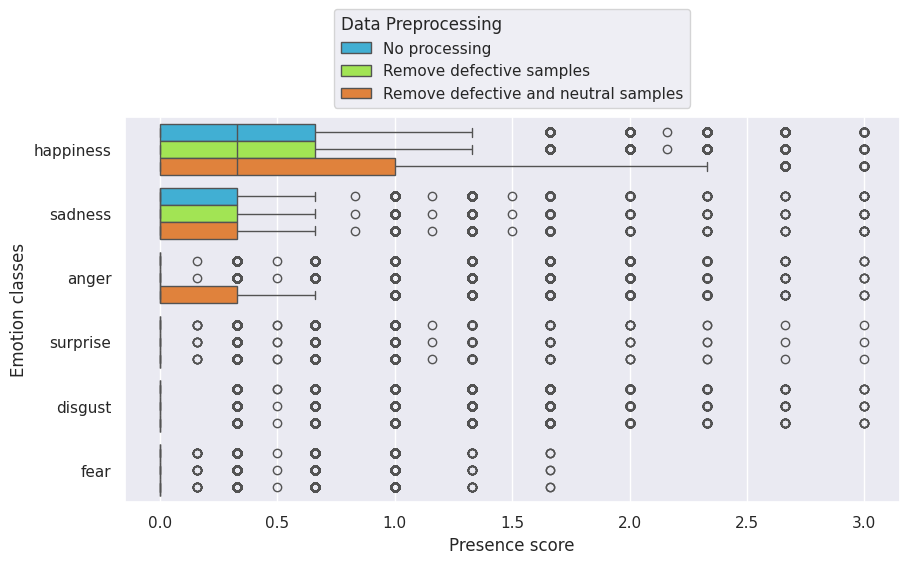

In [170]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.clf()
df = pd.concat({'proc_1':df_orig_all.melt(), 
                'proc_2': df_check_all.melt(), 
                'proc_3':df_task_all.melt()}, 
               names=['source', 'old_index'])
df = df.reset_index(level=0).reset_index(drop=True)
print(df.groupby(['source','variable'])['value'].describe())
ax = sns.boxplot(data=df, x='value', y='variable', hue='source', palette='turbo')

ax.set(xlabel='Presence score', ylabel='Emotion classes')

# # Medians
# medians = df.groupby(['source','variable'])['value'].median()
# vertical_offset = df['value'].median() * 0.05 # offset from median for display
# for xtick in ax.get_xticks():
#     ax.text(xtick,medians[xtick] + vertical_offset,medians[xtick], 
#             horizontalalignment='center',size='x-small',color='w',weight='semibold')

sns.set(rc={"figure.figsize":(10, 5)})
# Move legends   

handles, labels = ax.get_legend_handles_labels()
new_labels = ['No processing', 'Remove defective samples', 'Remove defective and neutral samples']  # Your custom labels
ax.legend(handles, new_labels, title='Data Preprocessing')
sns.move_legend(
    ax, loc='upper center',
    bbox_to_anchor=(.5, 1.3), frameon=True, alignment='left'
)
# ax.legend_.set(title='Data preprocess ing', label=["Millennial", "Older Generations", "hell)"])

# ax.legend.set_title("Data preprocessing")
# for label in ax.legend.texts:
#     if label.get_text() == "before_any_processing":
#         label.set_text("Before any prepocessing")
#     if label.get_text() == "remove_instances_failing_checking":
#         label.set_text("Remove any instances failing checking step")
#     else:
#        label.set_text("Remove any instances failing checking step + nentral instances") 

# plt.legend(title='Smoker', loc='upper left', labels=['Hell Yeh', 'Nah Bruh', 'hello'])

plt.savefig('boxplot.png', bbox_inches='tight')
plt.show()

# Count presence score for each class

In [17]:
def count_pairs_emotion_presence_score(y_array, all_scores):
    count_all = []
    for sc in all_scores:
        l = np.sum(y_array>sc, axis=0)
        count_all.append(l)
    count_all_arr = np.array(count_all)

    df_scores_all = pd.DataFrame(count_all_arr, 
                                 columns=['happiness', 'sadness', 'anger', 'surprise', 'disgust', 'fear'],
                                 index=all_scores)
    
    return df_scores_all

In [18]:
count_pairs_emotion_presence_score(y_all_orig, np.unique(y_all_orig))

,happiness,sadness,anger,surprise,disgust,fear
0.00,12459,5997,4995,2318,4097,1913
0.16,12436,5985,4994,2313,4097,1901
0.33,8009,3125,3032,704,2194,745
0.50,8000,3122,3031,702,2192,744
0.66,5349,1146,1656,204,1079,189
0.83,5343,1145,1656,204,1079,189
1.00,3541,404,604,67,515,16
1.16,3538,403,604,66,515,16
1.33,2208,169,311,29,259,3
1.50,2208,168,311,29,259,3


In [19]:
count_pairs_emotion_presence_score(y_all_orig, np.unique(y_all_orig))

,happiness,sadness,anger,surprise,disgust,fear
0.00,12459,5997,4995,2318,4097,1913
0.16,12436,5985,4994,2313,4097,1901
0.33,8009,3125,3032,704,2194,745
0.50,8000,3122,3031,702,2192,744
0.66,5349,1146,1656,204,1079,189
0.83,5343,1145,1656,204,1079,189
1.00,3541,404,604,67,515,16
1.16,3538,403,604,66,515,16
1.33,2208,169,311,29,259,3
1.50,2208,168,311,29,259,3


In [20]:
count_pairs_emotion_presence_score(y_all_task, np.unique(y_all_task))

,happiness,sadness,anger,surprise,disgust,fear
0.00,10907,5370,4494,2072,3748,1618
0.16,10887,5360,4493,2067,3748,1608
0.33,6945,2801,2750,628,2022,613
0.50,6938,2800,2749,626,2021,612
0.66,4619,1035,1505,189,995,157
0.83,4613,1034,1505,189,995,157
1.00,3052,369,562,61,476,13
1.16,3049,368,562,60,476,13
1.33,1910,156,288,26,233,2
1.50,1910,155,288,26,233,2


In [21]:
count_pairs_emotion_presence_score(y_all_task, np.unique(y_all_task))

,happiness,sadness,anger,surprise,disgust,fear
0.00,10907,5370,4494,2072,3748,1618
0.16,10887,5360,4493,2067,3748,1608
0.33,6945,2801,2750,628,2022,613
0.50,6938,2800,2749,626,2021,612
0.66,4619,1035,1505,189,995,157
0.83,4613,1034,1505,189,995,157
1.00,3052,369,562,61,476,13
1.16,3049,368,562,60,476,13
1.33,1910,156,288,26,233,2
1.50,1910,155,288,26,233,2


# Plot boxplot on the presence of emotion classes (based on threshold on presence score)

   happiness  sadness  anger  surprise  disgust  fear
0      10907     5370   4494      2072     3748  1618
1       3052      369    562        61      476    13
2        452       36     62         4       45     0
   happiness  sadness  anger  surprise  disgust  fear
0      62.04    30.54  25.56     11.78    21.32  9.20
1      17.36     2.10   3.20      0.35     2.71  0.07
2       2.57     0.20   0.35      0.02     0.26  0.00
number instances: 17582


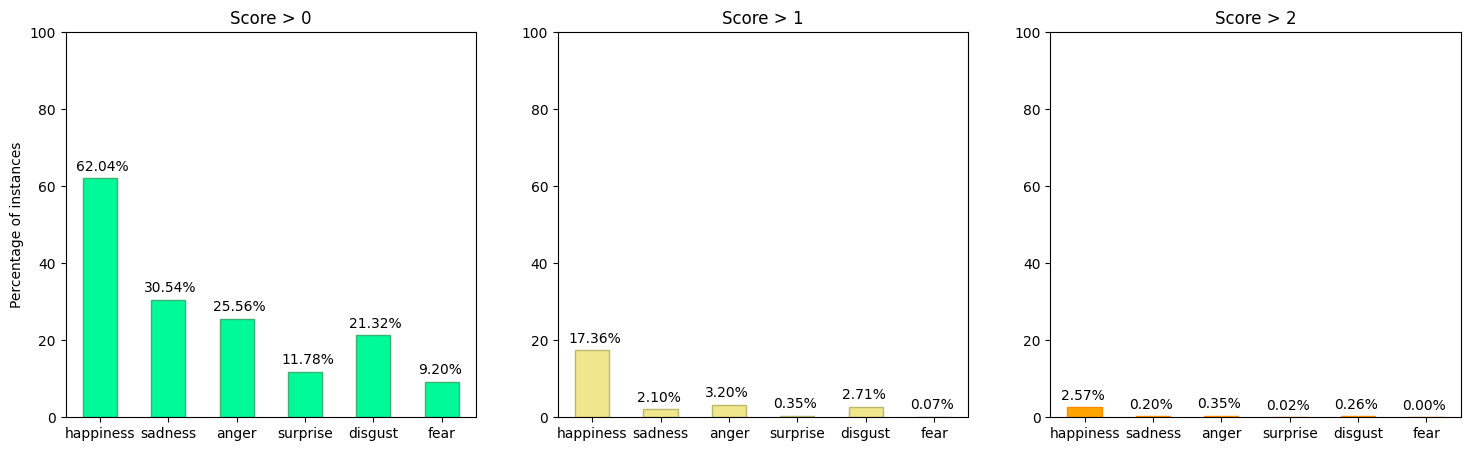

In [46]:
df_all_coa = count_pairs_emotion_presence_score(y_all_task, [0,1,2])
print(df_all_coa)
df_all_coa=((df_all_coa/y_all_task.shape[0])*100)
print(round(df_all_coa, 2))

print("number instances:", y_all_task.shape[0])
color = ['mediumspringgreen', 'khaki', 'orange', 'lightcoral']
coloredge = ['mediumseagreen', 'darkkhaki', 'darkorange', 'coral']

def plot_boxplot():
    fig, axs = plt.subplots(1, 3, figsize=(18,5))
    # fig, axs = plt.subplots(2, 2, figsize=(20,12))
    for i in range(3):
        ax_i = axs[i]
        ax = df_all_coa.iloc[i].plot(ax=ax_i, kind='bar', color=color[i], edgecolor=coloredge[i])
        for p in ax.patches:
            b = p.get_bbox()
            val = "{:.2f}%".format(b.y1 + b.y0)        
            ax.annotate(val, ((b.x0 + b.x1)/2 - 0.35, b.y1 + 2))
        ax_i.set_title("Score > {}".format(i))
        ax_i.set_ylim([0,100])
        ax_i.tick_params(axis='x', labelrotation=0)
        if i == 0:       
            ax_i.set_ylabel('Percentage of instances')
    # fig.suptitle("Count coarse scores")
    plt.savefig('histogram.png', bbox_inches='tight')
    plt.show()
    
plot_boxplot()

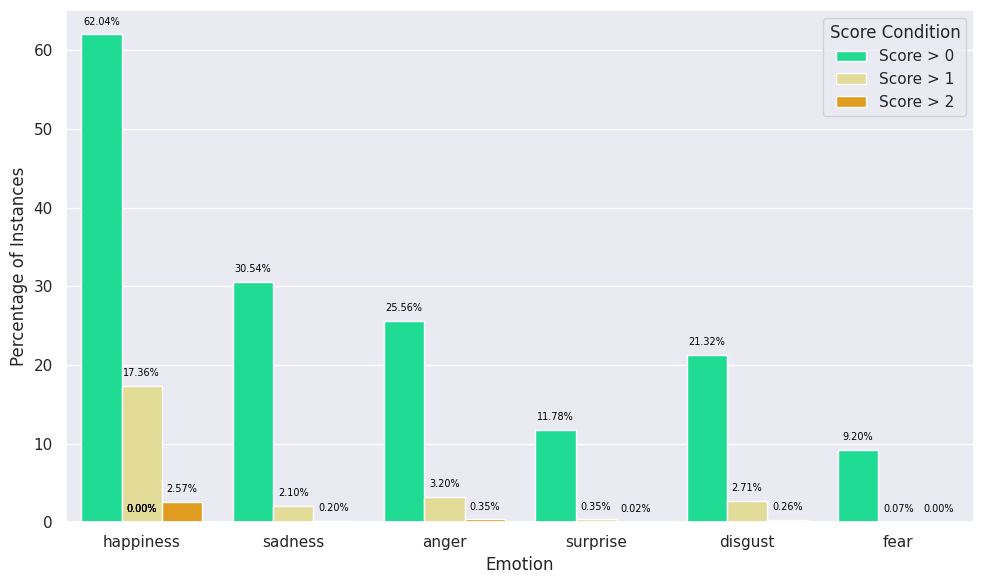

In [164]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Data for each score condition
data = {
    'emotion': ['happiness', 'sadness', 'anger', 'surprise', 'disgust', 'fear'],
    'Score > 0': [62.04, 30.54, 25.56, 11.78, 21.32, 9.20],
    'Score > 1': [17.36, 2.10, 3.20, 0.35, 2.71, 0.07],
    'Score > 2': [2.57, 0.20, 0.35, 0.02, 0.26, 0.00]
}

# Create a DataFrame
df = pd.DataFrame(data)

# Reshape the data into long-form
df_long = pd.melt(df, id_vars=['emotion'], value_vars=['Score > 0', 'Score > 1', 'Score > 2'],
                  var_name='score', value_name='percentage')

# Create a color palette for the three score conditions
# color = ['mediumspringgreen', 'khaki', 'orange', 'lightcoral']
# coloredge = ['mediumseagreen', 'darkkhaki', 'darkorange', 'coral']
palette = {'Score > 0': 'mediumspringgreen', 'Score > 1': 'khaki', 'Score > 2': 'orange'}
coloredge = {'Score > 0': 'mediumseagreen', 'Score > 1': 'darkkhaki', 'Score > 2': 'darkorange'}

# Create the barplot
plt.figure(figsize=(10, 6))
ax = sns.barplot(x='emotion', y='percentage', hue='score', data=df_long, palette=palette)
sns.set(rc={"figure.figsize":(8, 4)})

# for patch, label in zip(ax.patches, df_long['score']):
#     patch.set_edgecolor(edge_colors[label])

# Add percentage labels on top of each bar
for p in plt.gca().patches:
    plt.text(p.get_x() + p.get_width() / 2., p.get_height() + 1, f'{p.get_height():.2f}%', 
             ha='center', va='bottom', color='black', fontsize=7)

# Set axis labels and title
plt.xlabel('Emotion', fontsize=12)
plt.ylabel('Percentage of Instances', fontsize=12)
# plt.title('Emotion Distribution Across Different Scores', fontsize=14)

handles, labels = ax.get_legend_handles_labels()
new_labels = ['Score > 0', 'Score > 1', 'Score > 2']  # Your custom labels
ax.legend(handles, new_labels, title='Score Condition')

# Display the plot
plt.tight_layout()
plt.savefig("updated_boxplot.png")
plt.show()

# Boxplot on sequence lengths

22860
                  0
count  22860.000000
mean      26.092870
std       15.876056
min        1.000000
25%       16.000000
50%       23.000000
75%       32.000000
max      374.000000


/tmp/ipykernel_114248/2776275742.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=all_data, orient='h', palette="turbo")


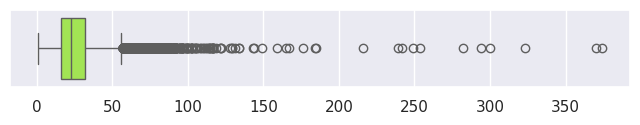

In [134]:
plt.clf()

a = train_list_orig[0] + valid_list_orig[0] + test_list_orig[0]
print(len(a))
all_data = [a_sample[0].shape[0] for a_sample in a]  # take test array
sns.boxplot(data=all_data, orient='h', palette="turbo")
sns.set(rc={"figure.figsize":(10, 1)}) #width=3, #height=4
df = pd.DataFrame(all_data)
print(df.describe())
plt.savefig('boxplot_sequences.png', bbox_inches='tight')
plt.show()